# Evaluate surrogate-screened search

Level: 3. Prerequisites: Levels 1 and 2 of this topic and level 3 of learning. Reading time: 26 minutes.

## Objectives

Compare the screened and unscreened search evidence in the same committed benchmark row, then interpret how the objective weight changes recovery-energy trade-offs.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/benchmark.json` stores the evaluated optimizer variants for twelve authored cases, MIT project licence. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

A surrogate-management framework may order proposed evaluations, but OreFlow still evaluates candidates with its process engine. The autoencoder guard and Gaussian-process interval limit screen proposals; the search poll remains authoritative. The weight path reports the conditional trade-off between recovered metal and specific energy. This notebook compares measured evaluation counts and baked path records; it claims no new optimization algorithm.

## Current methods and evidence

Generalized pattern search and progressive barriers are established derivative-free methods (Torczon, 1997; Audet and Dennis, 2009). Surrogate management can guide expensive design evaluations (Booker et al., 1999). OreFlow's evidence is case-specific: screened and unscreened runs reach the same recorded optimum on this row, while the recorded evaluation counts reveal whether screening saved work. This is not a proof for every case or an economic optimum.

Load the benchmark's screened-versus-unscreened comparison and report what the engine actually evaluated.

In [2]:
# Load the benchmark's screened-versus-unscreened comparison and report what the engine actually evaluated.
repo = Path('../../../').resolve()
benchmark = json.loads((repo / 'data/derived/benchmark.json').read_text(encoding='utf-8'))
row = benchmark['optimization']['copper_porphyry_soft']['nominal']
comparison = pd.DataFrame([
    {'search': 'surrogate screened', 'evaluations': row['evaluations']},
    {'search': 'unscreened', 'evaluations': row['evaluations_without_screen']},
])
print('same optimum:', row['same_optimum_without_screen'])
print('screen proposals:', row['proposed'], '| improved incumbents:', row['improved'])
print('engine evaluations saved:', row['evaluations_without_screen'] - row['evaluations'])
display(comparison)

same optimum: True
screen proposals: 72 | improved incumbents: 18
engine evaluations saved: -43


,search,evaluations
0,surrogate screened,309
1,unscreened,266


Plot the recorded weight path. Lower metal weight changes the objective; it does not alter the ore or plant model.

,weight,status,recovered_tph,energy_kwh_t
0,0.75,optimal,5.013899,10.213139
1,0.50,optimal,4.198802,7.349207
2,0.25,optimal,3.969572,7.102007


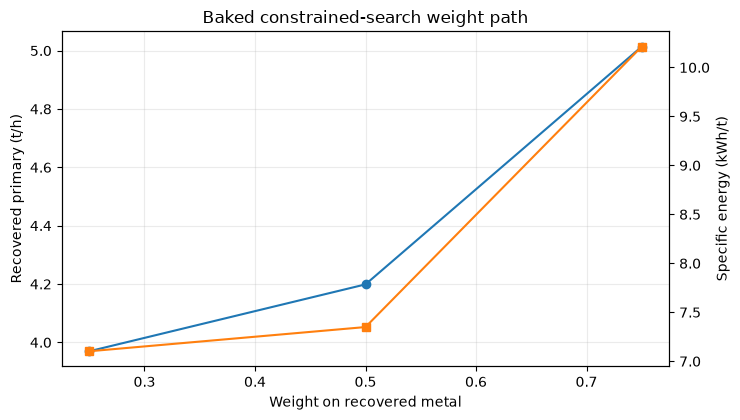

In [3]:
# Plot the recorded weight path.
path = pd.DataFrame(row['path'])
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(path['weight'], path['recovered_tph'], marker='o', label='recovered primary')
ax.set(xlabel='Weight on recovered metal', ylabel='Recovered primary (t/h)', title='Baked constrained-search weight path')
ax.grid(True, alpha=.25)
ax2 = ax.twinx(); ax2.plot(path['weight'], path['energy_kwh_t'], marker='s', color='tab:orange', label='specific energy')
ax2.set_ylabel('Specific energy (kWh/t)')
fig.tight_layout()
display(path)

Read evaluation saving beside the screened surrogate's absolute recovery error; neither quantity measures plant performance.

In [4]:
# Read evaluation saving beside the screened surrogate's absolute recovery error; neither quantity measures plant performance.
print('screened evaluations:', row['evaluations'])
print('unscreened evaluations:', row['evaluations_without_screen'])
print('surrogate absolute error (percentage points):', round(row['surrogate_abs_error_pp'], 4))
print('same optimum:', row['same_optimum_without_screen'])
print('limits: authored simulator cases only; no field calibration or economic objective')

screened evaluations: 309
unscreened evaluations: 266
surrogate absolute error (percentage points): 0.4126
same optimum: True
limits: authored simulator cases only; no field calibration or economic objective


## Results

The evaluation-count comparison measures computational work on one baked search. The weight path reveals the recovery-energy exchange under the engine's constraints. Neither the screened estimate error nor a matching endpoint says how a real plant would respond.

## Summary

You compared surrogate-assisted evaluation ordering with an engine-only search and inspected a baked objective path. The claim is narrow: methods are compared on OreFlow's authored cases, with no plant-validation claim.

## References

- https://doi.org/10.1137/S1052623493250780
- https://doi.org/10.1137/070692662
- https://doi.org/10.1007/BF01197708
- https://doi.org/10.1017/CBO9780511790423